# 68 Algorithms Challenge: Journey to Mastery
## Model 05: K-Nearest Neighbors (From-Scratch Classifier)

Author: Tyra Nyambura  
Date: 19th November, 2026  
Goal: Master our fifth model by implementing K-Nearest Neighbors entirely from scratch on the Wisconsin Breast Cancer Diagnostic dataset.

### The Challenge: Lazy Learning
KNN is a **lazy learner** - unlike Linear or Logistic Regression, it does not learn a set of weights during training. Instead, it simply stores the entire training set and judges a new point by finding its closest neighbours at prediction time. Today we will build the distance math and voting logic ourselves.

### Why KNN?
KNN makes no assumptions about the underlying data shape. It works by computing the straight-line distance between a new observation and every training example, selecting the `k` closest points, and taking a majority vote. It is intuitive, powerful, and a great exercise in understanding instance-based learning.


### Step 1: Loading our toolkit
We will use `numpy` for vectorised distance calculations, `Counter` from `collections` to perform the majority vote, and `scikit-learn` to handle the train/test split and evaluation metrics.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

### Step 2: Data loading & first impressions
Let's load the Wisconsin Breast Cancer Diagnostic dataset. We will drop the `id` column since it is just a patient identifier, and we will also drop the empty trailing column. We then inspect the shape and confirm there are no missing values.

In [2]:
data = pd.read_csv("../../data/breast-cancer-wisconsin-diagnostic/data.csv")

### Step 3: Train/test split & feature standardisation
We will apply an 80/20 train/test split with a fixed `random_state` for reproducibility. Because KNN relies on Euclidean distance, features with larger scales dominate the calculation - so we must standardise our features using a `StandardScaler` fitted on the training set only.

In [3]:
X = data.drop(columns=["id", "diagnosis", "Unnamed: 32"]).values
y = data["diagnosis"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

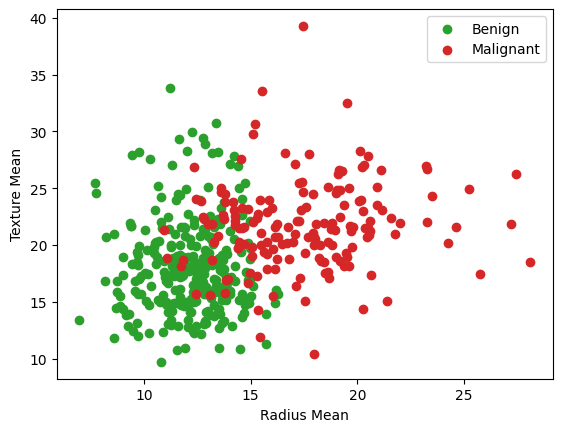

In [4]:
plt.scatter(
    X_train[y_train == "B", 0], X_train[y_train == "B", 1], color="tab:green", label="Benign"
)
plt.scatter(
    X_train[y_train == "M", 0], X_train[y_train == "M", 1], color="tab:red", label="Malignant"
)

plt.xlabel("Radius Mean")
plt.ylabel("Texture Mean")
plt.legend()
plt.show()

### Step 4: Building KNN from scratch
Here we implement the core algorithm. Our `KNN` class stores the training data on `fit()` and, on `predict()`, computes the Euclidean distance to every training point, sorts them, and takes the majority label among the `k` nearest.

#### The Euclidean Distance:
\[d(p, q) = \sqrt{\sum_{i=1}^{n} (p_i - q_i)^2}\]

* **In plain terms:** This is the straight-line distance in n-dimensional space - the Pythagorean theorem generalised to all 30 features.

In [5]:
def euclidean_distance(a, b):
    return np.sqrt(np.sum((b - a) ** 2))

In [6]:
class KNN:
    def __init__(self, k):
        self.k = k

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y

    def predict(self, new_points):
        predictions = [self.predict_class(new_point) for new_point in new_points]
        return np.array(predictions)

    def predict_class(self, new_point):
        distances = [euclidean_distance(point, new_point) for point in self.X_train]

        k_nearest_indices = np.argsort(distances)[: self.k]
        k_nearest_labels = [self.y_train[i] for i in k_nearest_indices]

        most_common = Counter(k_nearest_labels).most_common(1)[0][0]

        return most_common

### Step 5: Model evaluation
We will evaluate our from-scratch implementation across several `k` values. With well-separated classes you should see accuracy land in the **92–93%** range around `k = 5` or `k = 7`.

In [7]:
knn = KNN(5)
knn.fit(X_train, y_train)
predictions = knn.predict(X_test)
accuracy = np.mean(predictions == y_test) * 100
print(f"Accuracy: {accuracy:.2f}%")

Accuracy: 91.23%


### Step 6: Visualising predictions
Since we cannot visualise 30 dimensions, we project the test set onto `radius_mean` and `texture_mean` and colour our predictions. Correct classifications sit where expected; misclassifications stand out as markers.

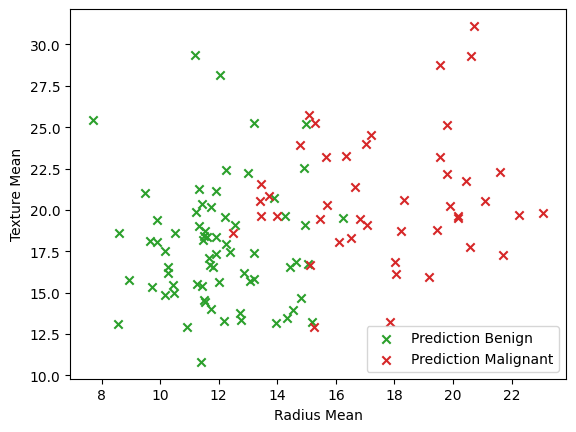

In [8]:
plt.scatter(
    X_test[predictions == "B", 0],
    X_test[predictions == "B", 1],
    color="tab:green",
    label="Prediction Benign",
    marker="x",
)
plt.scatter(
    X_test[predictions == "M", 0],
    X_test[predictions == "M", 1],
    color="tab:red",
    label="Prediction Malignant",
    marker="x",
)
plt.xlabel("Radius Mean")
plt.ylabel("Texture Mean")
plt.legend()
plt.show()